In [ ]:
import torch
import matplotlib.pyplot as plt

In [ ]:
def linear(m, x):
    return m@x

def add_one(x):
    x = x.tolist()
    x.append([1.]*n)
    x = torch.tensor(x)

    return x

def logistic(m, x):
    n = x.shape[1]

    return 1/(1 + torch.exp(-linear(m, x)))

def make_data(dim, n, mean1, mean2):
    data = {1 : [], 0 : []}
    for i in range(n):
        data[1].append((torch.randn(dim) + torch.tensor(mean1)).tolist())
    for i in range(n):
        data[0].append((torch.randn(dim) + torch.tensor(mean2)).tolist())

    data[0] = torch.tensor(data[0])
    data[1] = torch.tensor(data[1])

    return data

In [ ]:
n = 1000
data = make_data(3, n, torch.tensor([1, -2, 3]).float(), torch.tensor([-1, -2, -3]).float())

/tmp/ipykernel_3409/4244712322.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data[1].append((torch.randn(dim) + torch.tensor(mean1)).tolist())
/tmp/ipykernel_3409/4244712322.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data[0].append((torch.randn(dim) + torch.tensor(mean2)).tolist())


In [ ]:
data_cont = torch.tensor(data[0].tolist() + data[1].tolist())

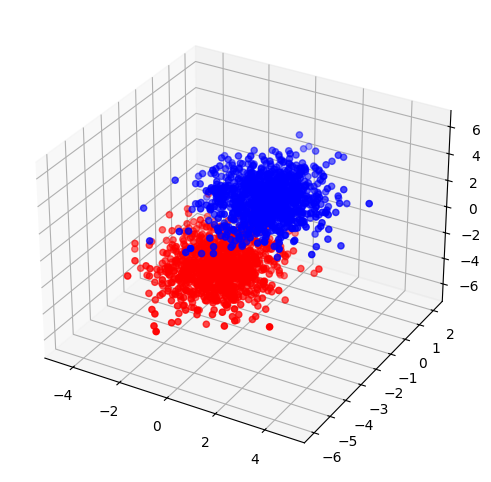

In [ ]:
# plt.scatter(data[0][:, 0], data[0][:, 1], c='red')
# plt.scatter(data[1][:, 0], data[1][:, 1], c='blue')

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc = ax.scatter(data[0][:, 0], data[0][:, 1], data[0][:, 2], c='red')
sc = ax.scatter(data[1][:, 0], data[1][:, 1], data[1][:, 2], c='blue')

In [ ]:
m = torch.tensor([0, 1, 2, 3]).float()
iterations = 10000
lr = 0.1

In [ ]:
ys = [0, 1]
xs = [data[0][:].T, data[1][:].T]

In [ ]:
for i in range(iterations):
    for y in ys:
        y_ = torch.tensor([y]*n)
        x = add_one(xs[y])
        dm = ((y_ - logistic(m, x))*x).mean(dim = 1)

        m += lr*dm

/tmp/ipykernel_3409/3395688415.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  Z = (m_prime@grid_input).reshape(X0.shape)


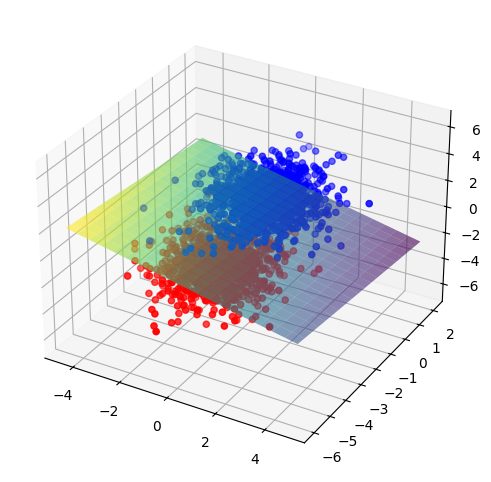

In [ ]:
import numpy as np

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc = ax.scatter(data[0][:, 0], data[0][:, 1], data[0][:, 2], c='red')
sc = ax.scatter(data[1][:, 0], data[1][:, 1], data[1][:, 2], c='blue')

x0_range = np.linspace(data_cont[:, 0].min(), data_cont[:, 0].max(), 20)
x1_range = np.linspace(data_cont[:, 1].min(), data_cont[:, 1].max(), 20)
X0, X1 = np.meshgrid(x0_range, x1_range)

m_prime = torch.tensor([-m[0].item()/m[2].item(), -m[1].item()/m[2].item(), (-m[3].item() + 0.5)/m[2].item()])
grid_input = np.vstack([X0.ravel(), X1.ravel(), np.ones(X0.size)])

Z = (m_prime@grid_input).reshape(X0.shape)
plane = ax.plot_surface(X0, X1, Z, cmap='viridis', alpha=0.6)

plt.show()